# Conda env Sara_batteries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import textwrap

import os
import sys
sys.path.append(os.path.abspath("../02_scripts"))

import utils
import config

df_data = utils.get_df_data()

print(df_data.columns)
df_data.head()

In [2]:
len(df_data)

128675

Model	Name	Notes
🟢 all-MiniLM-L6-v2	sentence-transformers/all-MiniLM-L6-v2	Light and fast
🟡 paraphrase-MiniLM-L3-v2	sentence-transformers/paraphrase-MiniLM-L3-v2	Lighter, lower accuracy
🔵 all-MiniLM-L12-v2	sentence-transformers/all-MiniLM-L12-v2	Slightly heavier, but should fit

/tmp/ipykernel_161909/10175760.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")


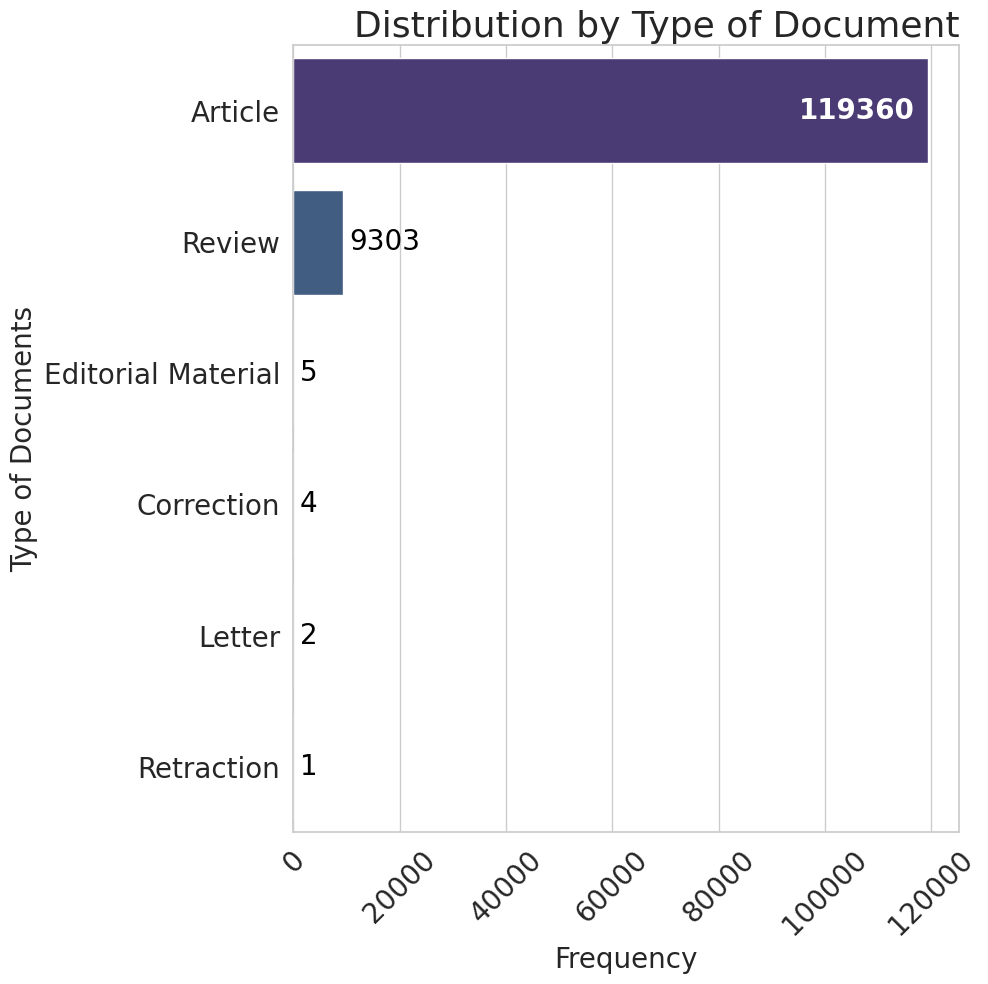

Document Type
Article               119360
Review                  9303
Editorial Material         5
Correction                 4
Letter                     2
Retraction                 1
Name: count, dtype: int64

\begin{tabular}{lr}
\toprule
Type of Documents & Frequency \\
\midrule
Article & 119360 \\
Review & 9303 \\
Editorial Material & 5 \\
Correction & 4 \\
Letter & 2 \\
Retraction & 1 \\
\bottomrule
\end{tabular}



In [ ]:
# Style
sns.set_theme(style="whitegrid")
fs1 = 26  # Title
fs2 = 20  # Axes
fs3 = 20  # Labels

# Preprocessing: handle multiple types separated by ";"
df_temp = df_data.copy()
df_temp[config.COLUMN_DOCUMENT_TYPE] = df_temp[config.COLUMN_DOCUMENT_TYPE].fillna("")
df_temp[config.COLUMN_DOCUMENT_TYPE] = df_temp[config.COLUMN_DOCUMENT_TYPE].apply(lambda x: re.sub(r'\s+', ' ', x))  # remove multiple spaces
df_temp[config.COLUMN_DOCUMENT_TYPE] = df_temp[config.COLUMN_DOCUMENT_TYPE].str.split(";")  # split types
df_temp[config.COLUMN_DOCUMENT_TYPE] = df_temp[config.COLUMN_DOCUMENT_TYPE].str[0]  # split types



# Count types
doc_counts = df_temp[config.COLUMN_DOCUMENT_TYPE].value_counts()


# Horizontal bar plot
plt.figure(figsize=(10, 10))
ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")
plt.title("Distribution by Type of Document", fontsize=fs1, loc="right")
plt.xlabel("Frequency", fontsize=fs2)
plt.ylabel("Type of Documents", fontsize=fs2)
plt.xticks(fontsize=fs2, rotation=45)
plt.yticks(fontsize=fs2)

# Add value labels
for i, v in enumerate(doc_counts.values):
    if i == 0:
        # Label inside bar in white (highest value)
        ax.text(v * 0.98, i, str(v), color='white', va='center', ha='right', fontsize=fs3, fontweight='bold')
    else:
        # Label outside bar in black
        ax.text(v + max(doc_counts.values) * 0.01, i, str(v), color='black', va='center', fontsize=fs3)

plt.tight_layout()

plt.savefig(f"{config.RESULTS_FOLDER}/distribution_type_of_document.pdf", bbox_inches='tight') #, dpi=300)


plt.show()

# Save to LaTeX
latex_table = doc_counts.reset_index()
latex_table.columns = ["Type of Documents", "Frequency"]
latex_code = latex_table.to_latex(index=False)

# print to screen
print(doc_counts)
print()
print(latex_code)

/tmp/ipykernel_229951/3603763344.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")


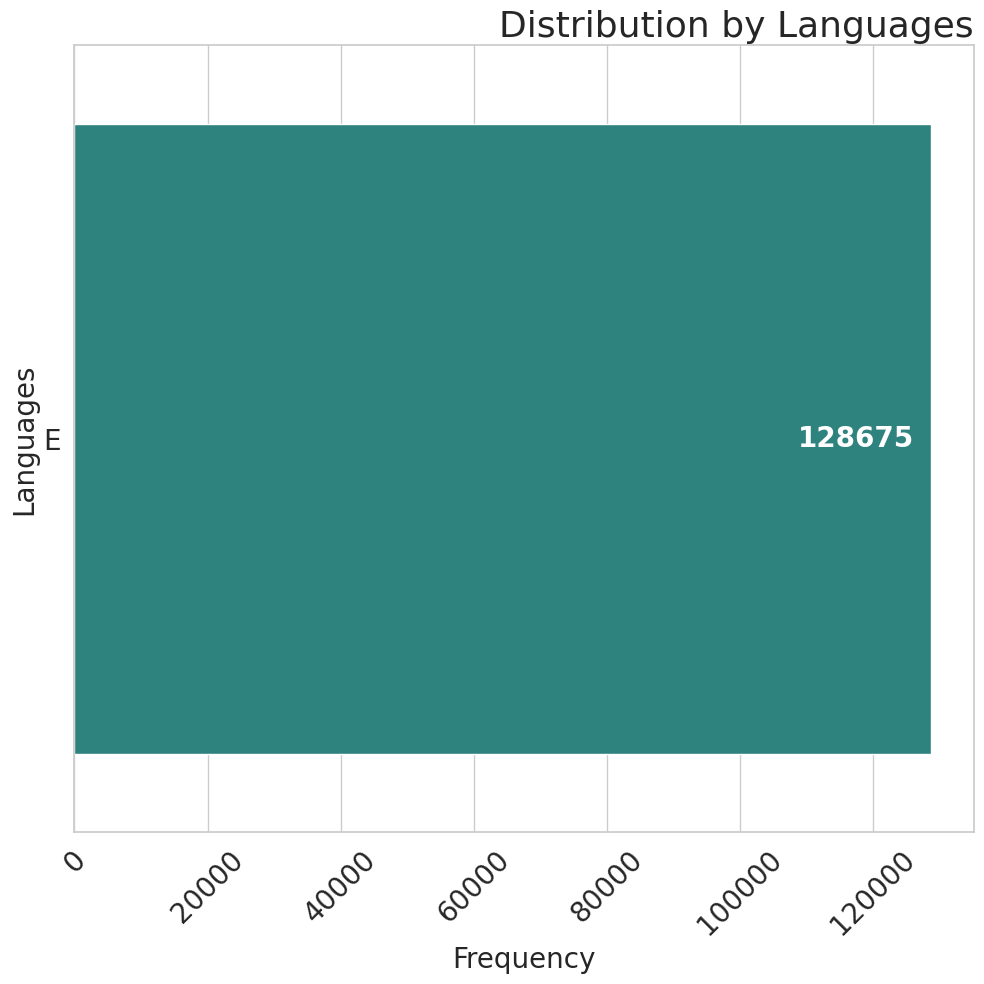

Language
E    128675
Name: count, dtype: int64

\begin{tabular}{lr}
\toprule
Languages & Frequency \\
\midrule
E & 128675 \\
\bottomrule
\end{tabular}



In [3]:
# Style
sns.set_theme(style="whitegrid")
fs1 = 26  # Title
fs2 = 20  # Axes
fs3 = 20  # Labels

# Preprocessing: handle multiple types separated by ";"
df_temp = df_data.copy()
df_temp[config.COLUMN_LANGUAGE] = df_temp[config.COLUMN_LANGUAGE].fillna("").apply(lambda x: x[0] if len(x) > 0 else "")
df_temp[config.COLUMN_LANGUAGE] = df_temp[config.COLUMN_LANGUAGE].apply(lambda x: re.sub(r'\s+', ' ', x))  # remove multiple spaces
df_temp[config.COLUMN_LANGUAGE] = df_temp[config.COLUMN_LANGUAGE].str.split(";")  # split types
df_temp[config.COLUMN_LANGUAGE] = df_temp[config.COLUMN_LANGUAGE].str[0]  # split types

# # Explode to transform lists into individual rows
# df_exploded = df_temp.explode(config.COLUMN_LANGUAGE)
# df_exploded[config.COLUMN_LANGUAGE] = df_exploded[config.COLUMN_LANGUAGE].str.strip()  # strip leading/trailing spaces
# df_exploded[config.COLUMN_LANGUAGE] = df_exploded[config.COLUMN_LANGUAGE].str.title()  # strip leading/trailing spaces

# Count types
doc_counts = df_temp[config.COLUMN_LANGUAGE].value_counts()

# Horizontal bar plot
plt.figure(figsize=(10, 10))
ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")
plt.title("Distribution by Languages", fontsize=fs1, loc="right")
plt.xlabel("Frequency", fontsize=fs2)
plt.ylabel("Languages", fontsize=fs2)
plt.xticks(fontsize=fs2, rotation=45)
plt.yticks(fontsize=fs2)

# Add value labels
for i, v in enumerate(doc_counts.values):
    if i == 0:
        # Label inside bar in white (highest value)
        ax.text(v * 0.98, i, str(v), color='white', va='center', ha='right', fontsize=fs3, fontweight='bold')
    else:
        # Label outside bar in black
        ax.text(v + max(doc_counts.values) * 0.01, i, str(v), color='black', va='center', fontsize=fs3)

plt.tight_layout()

plt.savefig(f'{config.RESULTS_FOLDER}/distribution_languages.pdf', bbox_inches='tight') #, dpi=300)

plt.show()

# Save to LaTeX
latex_table = doc_counts.reset_index()
latex_table.columns = ["Languages", "Frequency"]
latex_code = latex_table.to_latex(index=False)

# print to screen
print(doc_counts)
print()
print(latex_code)

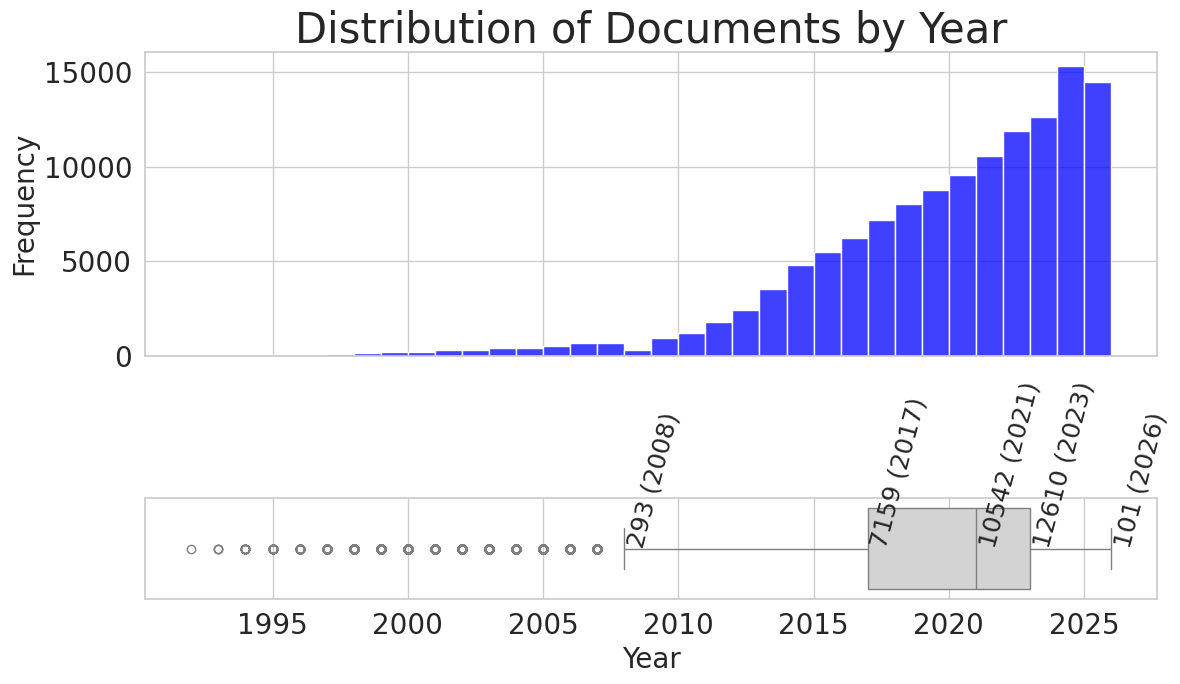

\begin{table}
\caption{Number of documents per year.}
\label{tab:documents_per_year}
\begin{tabular}{lr}
\toprule
Year & Documents \\
\midrule
1992 & 1 \\
1993 & 3 \\
1994 & 14 \\
1995 & 30 \\
1996 & 37 \\
1997 & 78 \\
1998 & 112 \\
1999 & 184 \\
2000 & 162 \\
2001 & 271 \\
2002 & 290 \\
2003 & 376 \\
2004 & 412 \\
2005 & 482 \\
2006 & 645 \\
2007 & 660 \\
2008 & 293 \\
2009 & 951 \\
2010 & 1208 \\
2011 & 1752 \\
2012 & 2409 \\
2013 & 3529 \\
2014 & 4777 \\
2015 & 5496 \\
2016 & 6227 \\
2017 & 7159 \\
2018 & 8035 \\
2019 & 8748 \\
2020 & 9556 \\
2021 & 10542 \\
2022 & 11866 \\
2023 & 12610 \\
2024 & 15294 \\
2025 & 14365 \\
2026 & 101 \\
\bottomrule
\end{tabular}
\end{table}



In [6]:
# Font sizes
fs1 = 30  # Title
fs2 = 20  # Axis labels and ticks
fs3 = 18  # Data labels

# Chart style
sns.set(style="whitegrid")

# Data
years = df_data[config.COLUMN_YEAR].dropna()

# Boxplot statistics
q1 = years.quantile(0.25)
q2 = years.median()
q3 = years.quantile(0.75)
iqr = q3 - q1
lower_whisker = max(years.min(), q1 - 1.5 * iqr)
upper_whisker = min(years.max(), q3 + 1.5 * iqr)

year_counts = years.value_counts().sort_index().to_dict()


# Figure
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Histogram
sns.histplot(years, bins=range(int(years.min()), int(years.max()) + 1), ax=ax1, color="blue")
ax1.set_ylabel("Frequency", fontsize=fs2)
ax1.set_title("Distribution of Documents by Year", fontsize=fs1)
ax1.tick_params(axis='both', labelsize=fs2)  # X and Y axis tick size for histogram

# Boxplot
sns.boxplot(x=years, ax=ax2, color="lightgray")
ax2.set_xlabel("Year", fontsize=fs2)
ax2.set_ylabel("")
ax2.tick_params(axis='both', labelsize=fs2)  # X and Y axis tick size for boxplot

# Labels on boxplot (values only, rotated)
for value in [lower_whisker, q1, q2, q3, upper_whisker]:
    ax2.text(value, 0.02, f"{year_counts[int(value)]:.0f} ({value:.0f})", ha='left', va='bottom', fontsize=fs3, rotation=75)

# Layout adjustment
plt.tight_layout()

plt.savefig(f'{config.RESULTS_FOLDER}/distribution_years.pdf', bbox_inches='tight') #, dpi=300)

plt.show()

# Convert to DataFrame
df_year_counts = (
    years.value_counts()
    .sort_index()
    .rename_axis("Year")
    .reset_index(name="Documents")
)

# Generate LaTeX table
latex_table = df_year_counts.to_latex(
    index=False,
    caption="Number of documents per year.",
    label="tab:documents_per_year",
    column_format="lr"
)

print(latex_table)

Total categories: WOS Categories
Materials Science, Multidisciplinary              62561
Chemistry, Physical                               49640
Energy & Fuels                                    30923
Electrochemistry                                  29050
Chemistry, Multidisciplinary                      23820
                                                  ...  
Marine & Freshwater Biology                           1
Fisheries                                             1
                                                      1
Humanities, Multidisciplinary                         1
Science Citation Index Expanded (SCI-EXPANDED)        1
Name: count, Length: 135, dtype: int64


/tmp/ipykernel_277232/3580827906.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")


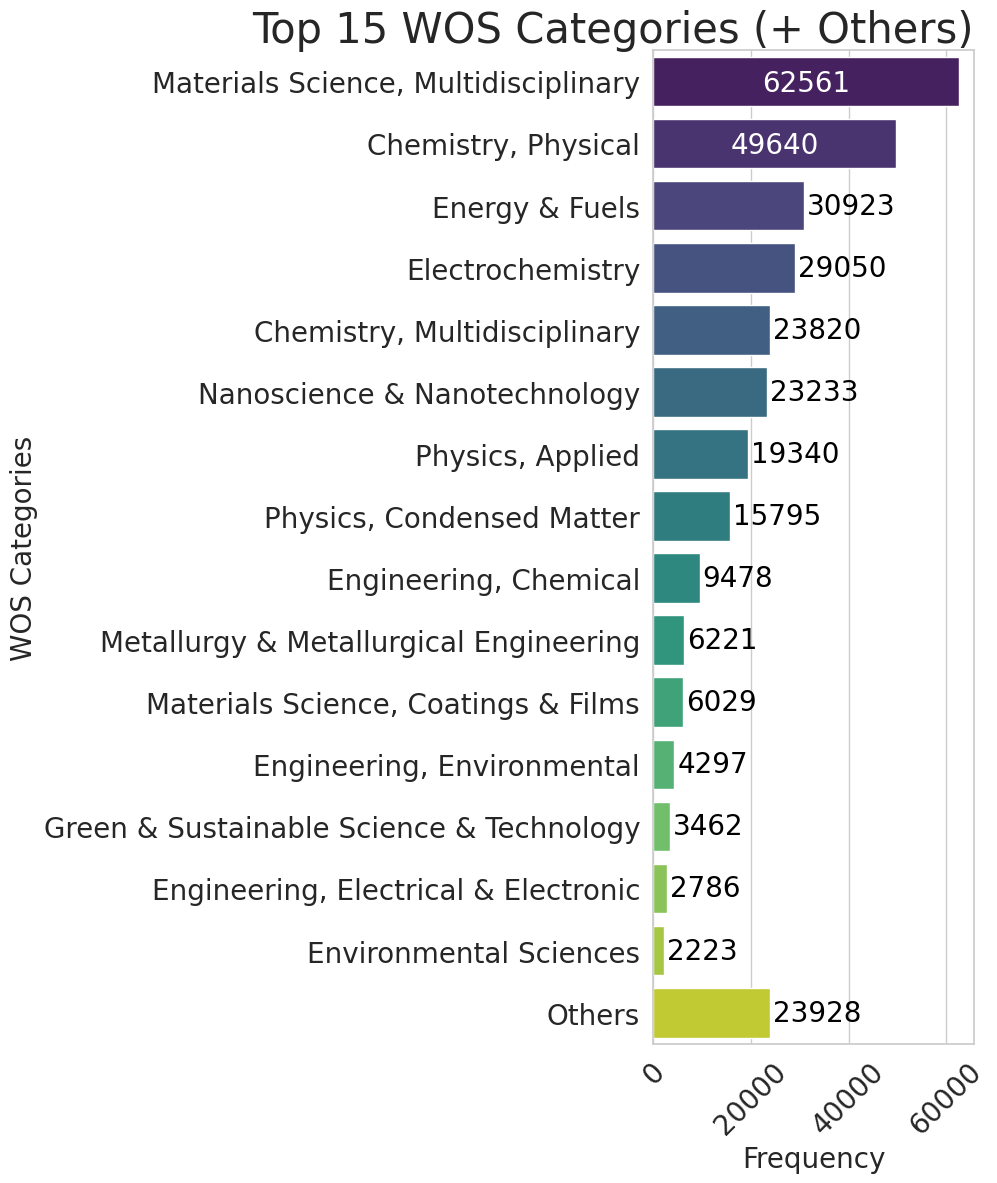

Materials Science, Multidisciplinary        62561
Chemistry, Physical                         49640
Energy & Fuels                              30923
Electrochemistry                            29050
Chemistry, Multidisciplinary                23820
Nanoscience & Nanotechnology                23233
Physics, Applied                            19340
Physics, Condensed Matter                   15795
Engineering, Chemical                        9478
Metallurgy & Metallurgical Engineering       6221
Materials Science, Coatings & Films          6029
Engineering, Environmental                   4297
Green & Sustainable Science & Technology     3462
Engineering, Electrical & Electronic         2786
Environmental Sciences                       2223
Others                                      23928
dtype: int64

\begin{tabular}{lr}
\toprule
WOS Category & Frequency \\
\midrule
Materials Science, Multidisciplinary & 62561 \\
Chemistry, Physical & 49640 \\
Energy & Fuels & 30923 \\
Electrochemistr

In [2]:
# Style
sns.set(style="whitegrid")
fs1 = 30  # Title
fs2 = 20  # Axes
fs3 = 20  # Labels
top_n = 15

# Preprocessing
df_temp = df_data.copy()

# Replace "\&" with "&" and normalize spaces
df_temp[config.COLUMN_WOS_CATEGORIES] = df_temp[config.COLUMN_WOS_CATEGORIES].fillna("")
df_temp[config.COLUMN_WOS_CATEGORIES] = df_temp[config.COLUMN_WOS_CATEGORIES].apply(
    lambda x: re.sub(r'\s+', ' ', x.replace("\\&", "&")).strip()
)

# Split categories by ';' and explode into multiple rows
df_temp[config.COLUMN_WOS_CATEGORIES] = df_temp[config.COLUMN_WOS_CATEGORIES].str.split(";")
df_exploded = df_temp.explode(config.COLUMN_WOS_CATEGORIES)

# Strip extra spaces and wrap text for plotting
df_exploded[config.COLUMN_WOS_CATEGORIES] = df_exploded[config.COLUMN_WOS_CATEGORIES].str.strip()
df_exploded[config.COLUMN_WOS_CATEGORIES] = df_exploded[config.COLUMN_WOS_CATEGORIES].apply(
    lambda x: textwrap.fill(x, width=50)
)

# Total count per category
total_counts = df_exploded[config.COLUMN_WOS_CATEGORIES].value_counts()
print(f"Total categories: {total_counts}")


# Separate top N and sum the rest as "Others"
doc_counts_top = total_counts.head(top_n)
doc_counts_other = total_counts.iloc[top_n:].sum()
doc_counts = pd.concat([doc_counts_top, pd.Series({"Others": doc_counts_other})])

# Horizontal bar plot
plt.figure(figsize=(10, 12))
ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")
plt.title(f"Top {top_n} WOS Categories (+ Others)", fontsize=fs1, loc="right")
plt.xlabel("Frequency", fontsize=fs2)
plt.ylabel("WOS Categories", fontsize=fs2)
plt.xticks(fontsize=fs2, rotation=45)
plt.yticks(fontsize=fs2)

# Add value labels
for i, (label, v) in enumerate(zip(doc_counts.index, doc_counts.values)):
    if i <= 1:
        ax.text(v / 2, i + 0.25, str(v), color='white', va='bottom', ha='center', fontsize=fs3)
    else:
        ax.text(v + max(doc_counts.values) * 0.01, i, str(v), color='black', va='center', fontsize=fs3)

plt.tight_layout()

plt.savefig(f'{config.RESULTS_FOLDER}/distribution_wos_categories.pdf', bbox_inches='tight') #, dpi=300)

plt.show()

# Save to LaTeX
latex_table = doc_counts.reset_index()
#latex_table = total_counts.reset_index()
latex_table.columns = ["WOS Category", "Frequency"]
latex_code = latex_table.to_latex(index=False)

# Print output
print(doc_counts)
print()
print(latex_code)

Total categories: Research Areas
Materials Science                        70458
Chemistry                                69644
Energy & Fuels                           30923
Electrochemistry                         29050
Science & Technology - Other Topics      28649
                                         ...  
Endocrinology & Metabolism                   1
Information Science & Library Science        1
Dermatology                                  1
Plant Sciences                               1
5P6JS                                        1
Name: count, Length: 77, dtype: int64


/tmp/ipykernel_368345/4226142447.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")


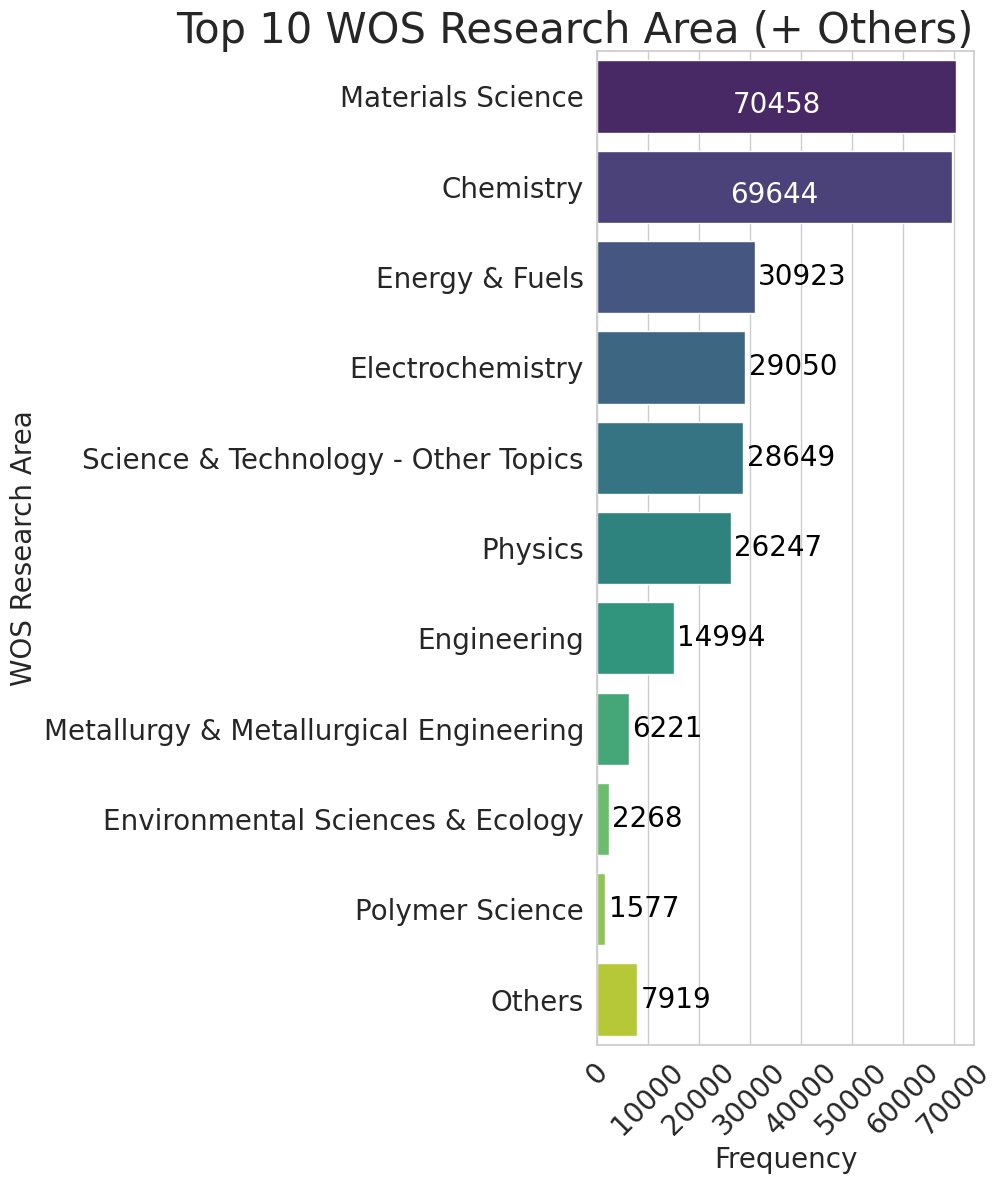

Materials Science                         70458
Chemistry                                 69644
Energy & Fuels                            30923
Electrochemistry                          29050
Science & Technology - Other Topics       28649
Physics                                   26247
Engineering                               14994
Metallurgy & Metallurgical Engineering     6221
Environmental Sciences & Ecology           2268
Polymer Science                            1577
Others                                     7919
dtype: int64

\begin{tabular}{lr}
\toprule
WOS Research Area & Frequency \\
\midrule
Materials Science & 70458 \\
Chemistry & 69644 \\
Energy & Fuels & 30923 \\
Electrochemistry & 29050 \\
Science & Technology - Other Topics & 28649 \\
Physics & 26247 \\
Engineering & 14994 \\
Metallurgy & Metallurgical Engineering & 6221 \\
Environmental Sciences & Ecology & 2268 \\
Polymer Science & 1577 \\
Others & 7919 \\
\bottomrule
\end{tabular}



In [3]:
# Style
sns.set_theme(style="whitegrid")
fs1 = 30  # Title
fs2 = 20  # Axes
fs3 = 20  # Labels
top_n = 10
field = config.COLUMN_WOS_RESEARCH_AREAS
field_title = "WOS Research Area"

# Preprocessing
df_temp = df_data.copy()

# Replace "\&" with "&" and normalize spaces
df_temp[field] = df_temp[field].fillna("")
df_temp[field] = df_temp[field].apply(
    lambda x: re.sub(r'\s+', ' ', x.replace("\\&", "&")).strip()
)

# Split categories by ';' and explode into multiple rows
df_temp[field] = df_temp[field].str.split(";")
df_exploded = df_temp.explode(field)

# Strip extra spaces and wrap text for plotting
df_exploded[field] = df_exploded[field].str.strip()
df_exploded[field] = df_exploded[field].apply(
    lambda x: textwrap.fill(x, width=50)
)

# Total count per category
total_counts = df_exploded[field].value_counts()
print(f"Total categories: {total_counts}")


# Separate top N and sum the rest as "Others"
doc_counts_top = total_counts.head(top_n)
doc_counts_other = total_counts.iloc[top_n:].sum()
doc_counts = pd.concat([doc_counts_top, pd.Series({"Others": doc_counts_other})])

# Horizontal bar plot
plt.figure(figsize=(10, 12))
ax = sns.barplot(x=doc_counts.values, y=doc_counts.index, palette="viridis")
plt.title(f"Top {top_n} {field_title} (+ Others)", fontsize=fs1, loc="right")
plt.xlabel("Frequency", fontsize=fs2)
plt.ylabel(field_title, fontsize=fs2)
plt.xticks(fontsize=fs2, rotation=45)
plt.yticks(fontsize=fs2)

# Add value labels
for i, (label, v) in enumerate(zip(doc_counts.index, doc_counts.values)):
    if i <=1 :
        ax.text(v / 2, i + 0.25, str(v), color='white', va='bottom', ha='center', fontsize=fs3)
    else:
        ax.text(v + max(doc_counts.values) * 0.01, i, str(v), color='black', va='center', fontsize=fs3)

plt.tight_layout()

plt.savefig(f'{config.RESULTS_FOLDER}/distribution_wos_research_area.pdf', bbox_inches='tight') #, dpi=300)

plt.show()

# Save to LaTeX
latex_table = doc_counts.reset_index()
#latex_table = total_counts.reset_index()
latex_table.columns = [field_title, "Frequency"]
latex_code = latex_table.to_latex(index=False)

# Print output
print(doc_counts)
print()
print(latex_code)

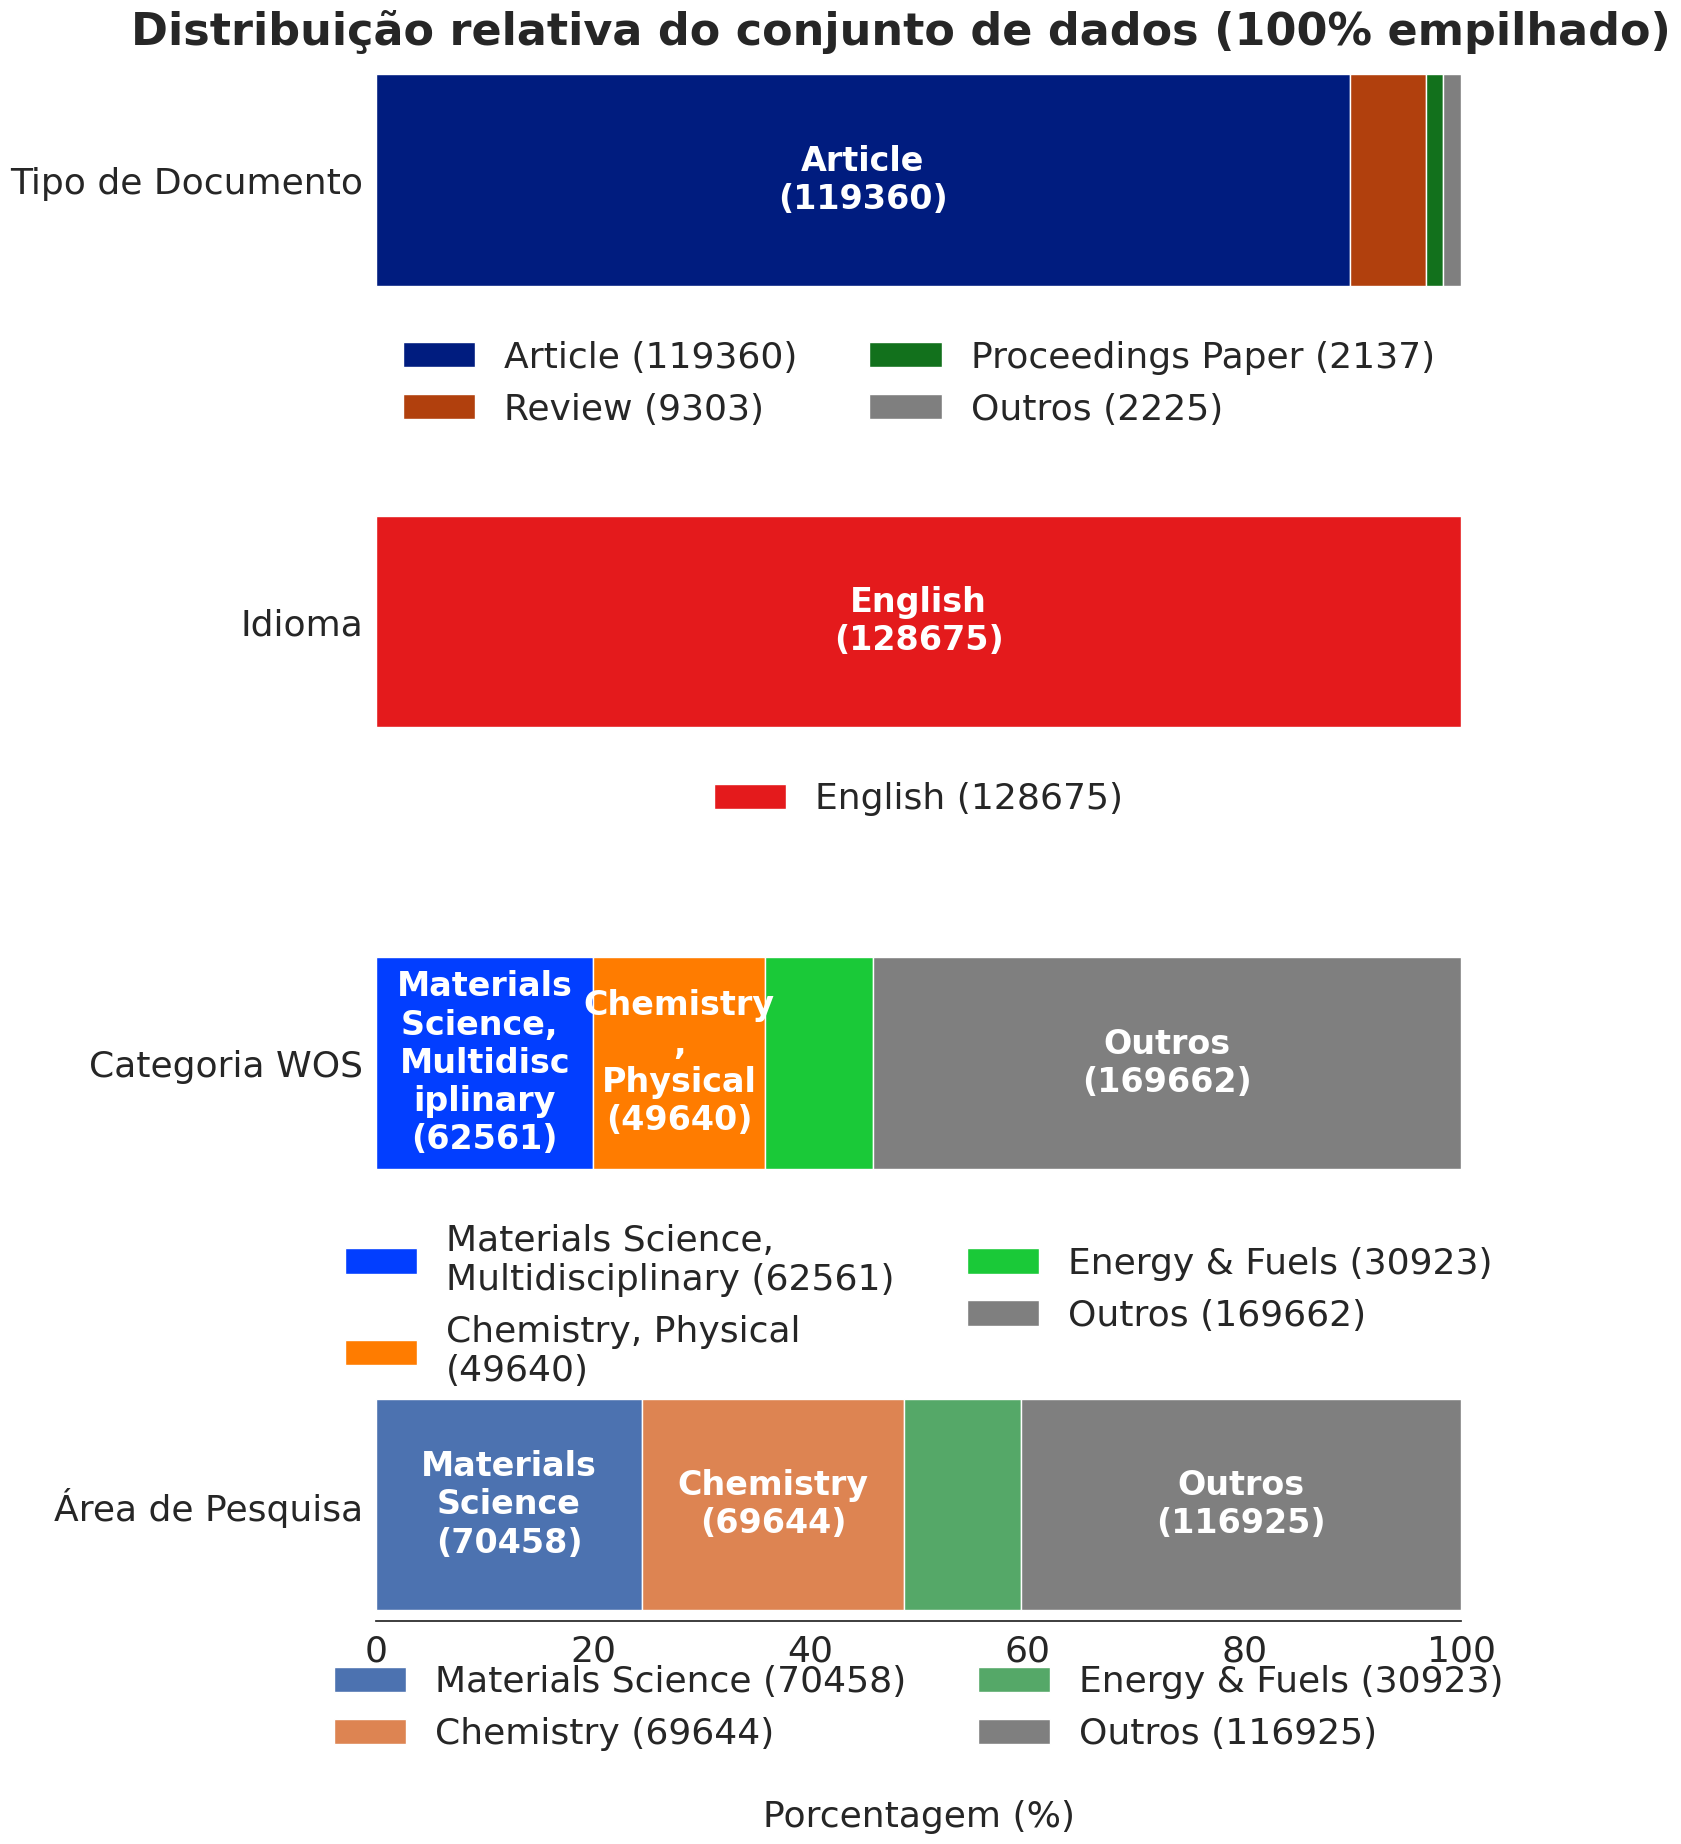


Chart saved successfully 
Corrected LaTeX table saved


In [7]:


# Base style settings
sns.set_theme(style="white")
fs1 = 32  # Title
fs2 = 26  # Axes and Legend
fs3 = 24  # Inner labels

msg = {
    "sup_title": ("Dataset Composition Overview (100% Stacked)", "Dataset Composition Overview (100% Stacked)"),
    "x_label": ("Percentage (%)", "Percentage (%)"),
    "doc_type": ("Type of Document", "Type of Document"),
    "language": ("Language", "Language"),
    "wos_category": ("WOS Category", "WOS Category"),
    "research_area": ("Research Area", "Research Area"),
    "outros": ("Others", "Others")
}
lang = 1


# -----------------------------------------------------------------------------
# 1. DATA PREPROCESSING
# -----------------------------------------------------------------------------
processed_data = {}

# --- Document Type ---
df_doc = df_data.copy()
df_doc[config.COLUMN_DOCUMENT_TYPE] = df_doc[config.COLUMN_DOCUMENT_TYPE].fillna("").apply(lambda x: re.sub(r'\s+', ' ', x)).str.split(";")
df_doc = df_doc.explode(config.COLUMN_DOCUMENT_TYPE)
df_doc[config.COLUMN_DOCUMENT_TYPE] = df_doc[config.COLUMN_DOCUMENT_TYPE].str.strip()
counts_doc = df_doc[config.COLUMN_DOCUMENT_TYPE].value_counts()

# --- Languages ---
df_lang = df_data.copy()
#df_lang[config.COLUMN_LANGUAGE] = df_lang[config.COLUMN_LANGUAGE].fillna("").apply(lambda x: x[0] if len(x) > 0 else "")
#df_lang[config.COLUMN_LANGUAGE] = df_lang[config.COLUMN_LANGUAGE].apply(lambda x: re.sub(r'\s+', ' ', x)).str.split(";")
df_lang[config.COLUMN_LANGUAGE] = (df_lang[config.COLUMN_LANGUAGE].apply(lambda x: re.sub(r'\s+', ' ', x)).str.split(";").str[0])
df_lang = df_lang.explode(config.COLUMN_LANGUAGE)
df_lang[config.COLUMN_LANGUAGE] = df_lang[config.COLUMN_LANGUAGE].str.strip().str.title()
counts_lang = df_lang[config.COLUMN_LANGUAGE].value_counts()

# --- WOS Categories ---
df_cat = df_data.copy()
df_cat[config.COLUMN_WOS_CATEGORIES] = df_cat[config.COLUMN_WOS_CATEGORIES].fillna("").apply(lambda x: re.sub(r'\s+', ' ', x.replace("\\&", "&")).strip()).str.split(";")
df_cat = df_cat.explode(config.COLUMN_WOS_CATEGORIES)
df_cat[config.COLUMN_WOS_CATEGORIES] = df_cat[config.COLUMN_WOS_CATEGORIES].str.strip()
counts_cat = df_cat[config.COLUMN_WOS_CATEGORIES].value_counts()

# --- Research Areas ---
df_area = df_data.copy()
df_area[config.COLUMN_WOS_RESEARCH_AREAS] = df_area[config.COLUMN_WOS_RESEARCH_AREAS].fillna("").apply(lambda x: re.sub(r'\s+', ' ', x.replace("\\&", "&")).strip()).str.split(";")
df_area = df_area.explode(config.COLUMN_WOS_RESEARCH_AREAS)
df_area[config.COLUMN_WOS_RESEARCH_AREAS] = df_area[config.COLUMN_WOS_RESEARCH_AREAS].str.strip()
counts_area = df_area[config.COLUMN_WOS_RESEARCH_AREAS].value_counts()

dimensions = {
    msg["doc_type"][lang]: counts_doc,
    msg["language"][lang]: counts_lang,
    msg["wos_category"][lang]: counts_cat,
    msg["research_area"][lang]: counts_area
}

# Strong and distinct color palettes
palettes = {
    msg["doc_type"][lang]: sns.color_palette("dark", 4),       
    msg["language"][lang]: sns.color_palette("Set1", 4),            
    msg["wos_category"][lang]: sns.color_palette("bright", 4),      
    msg["research_area"][lang]: sns.color_palette("deep", 4)        
}

final_df_list = []
plot_structure = {}

for dim_name, counts in dimensions.items():
    # # For the full LaTeX table
    # df_dim = counts.reset_index()
    # df_dim.columns = ["Category", "Frequency"]
    # df_dim.insert(0, "Dimension", dim_name)
    # final_df_list.append(df_dim)
    
    # # Processing Top 3 + Others for the chart
    # top3 = counts.head(3)
    # others_sum = counts.iloc[3:].sum()
    # combined = pd.concat([top3, pd.Series({msg["outros"][lang]: others_sum})]) if others_sum > 0 else top3
    top3 = counts.head(3)
    others_sum = counts.iloc[3:].sum()

    combined = (
        pd.concat([top3, pd.Series({msg["outros"][lang]: others_sum})])
        if others_sum > 0
        else top3
    )

    # Use the same chart data in the table
    df_dim = combined.reset_index()
    df_dim.columns = ["Category", "Frequency"]
    df_dim.insert(0, "Dimension", dim_name)

    final_df_list.append(df_dim)


    total = combined.sum()
    percentages = (combined / total) * 100
    
    plot_structure[dim_name] = {
        "categories": percentages.index.tolist(),
        "percentages": percentages.values.tolist(),
        "absolutes": combined.values.tolist()
    }

# -----------------------------------------------------------------------------
# 2. CHART GENERATION (4 Subplots with new text formatting)
# -----------------------------------------------------------------------------

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 18), sharex=True)
fig.suptitle(msg["sup_title"][lang], fontsize=fs1, y=0.91, weight='bold')

for idx, (dim_name, data) in enumerate(plot_structure.items()):
    ax = axes[idx]
    left = 0
    dim_colors = palettes[dim_name]
    
    handles = []
    legend_labels = []  # List to store the new formatted legend strings
    
    for c_idx, (cat, pct, abs_val) in enumerate(zip(data["categories"], data["percentages"], data["absolutes"])):
        color = "#7f7f7f" if cat == msg["outros"][lang] else dim_colors[c_idx % len(dim_colors)]
        
        # Draw bar segment
        bar = ax.barh([dim_name], pct, left=left, color=color, edgecolor='white', height=0.8)
        handles.append(bar[0])
        
        # 1) New string for Legend: "Category (Value)"
        if len(f"{cat} ({abs_val})") > 25:
            wrapped_cat = textwrap.fill(f"{cat} ({abs_val})", width=25)
            legend_labels.append(wrapped_cat)
        else:
            legend_labels.append(f"{cat} ({abs_val})")
            
        
        # 2) New string for inner bar labels (only if it fits)
        if abs_val >= 40000: #if pct > 6:  # Slightly raised threshold to 6% to leave room for larger text
            text_color = 'white' #if cat != msg["outros"][lang] and dim_name in [msg["doc_type"][lang], msg["research_area"][lang]] else 'black'
            
            # Wrap category name so it does not overflow block width
            wrapped_cat = textwrap.fill(cat, width=9)
            bar_text = f"{wrapped_cat}\n({abs_val})"
            
            ax.text(left + pct/2, 0, bar_text, 
                    va='center', ha='center', color=text_color, 
                    fontsize=fs3, weight='bold')
            
        left += pct

    # Apply custom legends with "Name (Count)" pattern below each bar
    ax.legend(handles, legend_labels, 
              loc="upper center",                  # Legend anchor point
              bbox_to_anchor=(0.5, -0.05),       # (X=Bar center, Y=Below bar)
              ncol=2, #len(data["categories"]),      # Place items horizontally (side by side)
              title_fontsize=fs2, fontsize=fs2, 
              frameon=False, shadow=False, facecolor='#fcfcfc')    
    
    # Clean up axes
    ax.set_xlim(0, 100)
    ax.tick_params(axis='y', labelsize=fs2, labelleft=True)
    ax.tick_params(axis='x', labelsize=fs2)
    sns.despine(ax=ax, left=True, bottom=True, top=True, right=True)
    ax.grid(False)

# Bottom axis adjustment
axes[-1].set_xlabel(msg["x_label"][lang], fontsize=fs2, labelpad=95)
sns.despine(ax=axes[-1], left=True, bottom=False, top=True, right=True)

plt.subplots_adjust(hspace=0.9, bottom=0.015)
#plt.tight_layout()

# Save Chart
plt.savefig(f'{config.RESULTS_FOLDER}/documents_distribution.pdf', bbox_inches='tight') #, dpi=300)
plt.show()

# -----------------------------------------------------------------------------
# 3. UNIFIED LATEX TABLE GENERATION GROUPED BY SECTIONS (FIXED)
# -----------------------------------------------------------------------------
df_dim["Percentage"] = (combined / combined.sum() * 100).round(2).values

# Build LaTeX code manually with proper longtable syntax
latex_lines = [
    r"\begin{longtable}{lr}",
    r"\caption{Detailed distribution of documents across different dimensions (document type, language, categories, and research areas).}",
    r"\label{tab:documents_distribution} \\",
    r"\toprule",
    r"\textbf{Category} & \textbf{Frequency} \\",
    r"\midrule",
    r"\endfirsthead",  # First page header
    r"\columnproperties",
    r"\toprule",
    r"\textbf{Category} & \textbf{Frequency} (Continued) \\",
    r"\midrule",
    r"\endhead",      # Subsequent pages header (in case of page break)
    r"\midrule",
    r"\multicolumn{2}{r}{\textit{Continued on next page}} \\",
    r"\bottomrule",
    r"\endfoot",      # Footer for all pages except the last
    r"\bottomrule",
    r"\endlastfoot"   # Footer for the last page of the table
]

# Iterate over each dimension dataframe generated in step 1
for i, df_dim in enumerate(final_df_list):
    # Get current dimension name (e.g., "Document Type")
    dim_name = df_dim["Dimension"].iloc[0]
    
    # If not the first section, add a separator line
    if i > 0:
        latex_lines.append(r"\midrule")
        
    # Add bold section header row spanning both columns
    latex_lines.append(f"\\multicolumn{{2}}{{l}}{{\\textbf{{{dim_name}}}}} \\\\")
    latex_lines.append(r"\midrule")
    
    # Add data rows for this dimension
    for _, row in df_dim.iterrows():
        # Escape special LaTeX characters to avoid compilation errors
        category = str(row["Category"]).replace("&", r"\&").replace("_", r"\_")
        frequency = row["Frequency"]
        latex_lines.append(f"{category} & {frequency} \\\\")

# Close table structure
latex_lines.append(r"\end{longtable}")

# Join all lines into a single LaTeX code string
latex_code = "\n".join(latex_lines)

# Save single .tex file
table_path = f'{config.RESULTS_FOLDER}/documents_distribution.tex'
with open(table_path, 'w', encoding='utf-8') as f:
    f.write(latex_code)

print(f"\nChart saved successfully ")
print(f"Corrected LaTeX table saved")